## Assignment 4: NLP and Time Series Models in Finance


## Question 1 (20 points) — Financial Text Classification
Compare a finance-domain model with a simple text baseline on financial headlines.

(a) (4 pts) Load the dataset, report class counts and shares, show a few example headlines, and report a majority-class baseline.

In [110]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import yfinance as yf
from torch.utils.data import DataLoader, Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, balanced_accuracy_score,
    recall_score, confusion_matrix, roc_auc_score, ConfusionMatrixDisplay, mean_squared_error
)
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.utils.class_weight import compute_class_weight
from scipy.stats import pearsonr

# Set device for PyTorch
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

Using device: cpu


In [111]:
file_path_q1 = '/content/sample_data/HW4 data Q1.csv'
df_q1 = pd.read_csv(file_path_q1, encoding='latin1')

df_q1.head()

,neutral,"According to Gran , the company has no plans to move all production to Russia , although that is where the company is growing ."
0,neutral,Technopolis plans to develop in stages an area...
1,negative,The international electronic industry company ...
2,positive,With the new production plant the company woul...
3,positive,According to the company 's updated strategy f...
4,positive,FINANCING OF ASPOCOMP 'S GROWTH Aspocomp is ag...


In [112]:
df_q1.columns = ['label', 'headline']

print(df_q1.head())
print(df_q1['label'].value_counts())
print(df_q1['label'].value_counts(normalize=True))

majority_acc = df_q1['label'].value_counts(normalize=True).max()
print("Majority baseline:", majority_acc)

      label                                           headline
0   neutral  Technopolis plans to develop in stages an area...
1  negative  The international electronic industry company ...
2  positive  With the new production plant the company woul...
3  positive  According to the company 's updated strategy f...
4  positive  FINANCING OF ASPOCOMP 'S GROWTH Aspocomp is ag...
label
neutral     2878
positive    1363
negative     604
Name: count, dtype: int64
label
neutral     0.594014
positive    0.281321
negative    0.124665
Name: proportion, dtype: float64
Majority baseline: 0.5940144478844169


(b) (4 pts) Evaluate FinBERT (or an equivalent finance-domain pretrained transformer) on one fixed stratified split and report accuracy, macro-F1, balanced accuracy, and per-class recall.

In [113]:
X_train, X_test, y_train, y_test = train_test_split(
    df_q1['headline'], df_q1['label'],
    test_size=0.2,
    stratify=df_q1['label'],
    random_state=42)

In [114]:
model_name = 'ProsusAI/finbert'
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name).to(device)

def finbert_predict(texts, batch_size=32):
    model.eval()
    all_preds = []
    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            batch = texts[i : i + batch_size]
            inputs = tokenizer(batch, return_tensors='pt', truncation=True, padding=True).to(device)
            outputs = model(**inputs)
            p = torch.softmax(outputs.logits, dim=1).cpu().numpy()
            all_preds.extend(np.argmax(p, axis=1))

    id_to_label = model.config.id2label
    return [id_to_label[p] for p in all_preds]

y_pred_fb = finbert_predict(X_test.tolist())

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: ProsusAI/finbert
Key                          | Status     |  | 
-----------------------------+------------+--+-
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [115]:
print(f"Accuracy: {accuracy_score(y_test, y_pred_fb):.4f}")
print(f"Macro F1: {f1_score(y_test, y_pred_fb, average='macro'):.4f}")
print(f"Balanced Acc: {balanced_accuracy_score(y_test, y_pred_fb):.4f}")

# Per-class recall
labels = ['neutral', 'positive', 'negative']
recalls = recall_score(y_test, y_pred_fb, average=None, labels=labels)
for label, rec in zip(labels, recalls):
    print(f"Recall for {label}: {rec:.4f}")

Accuracy: 0.8896
Macro F1: 0.8818
Balanced Acc: 0.9119
Recall for neutral: 0.8681
Recall for positive: 0.9007
Recall for negative: 0.9669


(c) (4 pts) Build a bag-of-words + logistic-regression baseline on the exact same split and explain why it is still a useful benchmark.

In [116]:
vectorizer = TfidfVectorizer(max_features=5000)
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

log_reg_model = LogisticRegression(max_iter=1000, random_state=42, solver='liblinear')
log_reg_model.fit(X_train_vec, y_train)
y_pred_log_reg = log_reg_model.predict(X_test_vec)

print(f"BoW + Logistic Regression Result")
print(f"Accuracy: {accuracy_score(y_test, y_pred_log_reg):.4f}")
print(f"Macro-F1: {f1_score(y_test, y_pred_log_reg, average='macro'):.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_test, y_pred_log_reg):.4f}")

labels = ['neutral', 'positive', 'negative']
recalls_lr = recall_score(y_test, y_pred_log_reg, average=None, labels=labels)
for label, rec in zip(labels, recalls_lr):
    print(f"Recall for {label}: {rec:.4f}")

BoW + Logistic Regression Result
Accuracy: 0.7451
Macro-F1: 0.6412
Balanced Accuracy: 0.6005
Recall for neutral: 0.9601
Recall for positive: 0.4449
Recall for negative: 0.3967


### Why BoW + Logistic Regression is a Useful Benchmark

It provides a clear, transparent baseline for text patterns and allowing for rapid iteration and testing. It also helps identify if gains from Transformers come from semantic understanding or just simple keyword matching.

(d) (4 pts) Compare both models with one common metric table, confusion matrices, and a few disagreement examples. State clearly if one model is still leaning too hard on the neutral class.

In [117]:
def get_metrics(y_true, y_pred):
    labels = ['neutral', 'positive', 'negative']
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, average='macro')
    bal_acc = balanced_accuracy_score(y_true, y_pred)
    recalls = recall_score(y_true, y_pred, average=None, labels=labels)
    return [acc, f1, bal_acc] + list(recalls)

metrics_finbert = get_metrics(y_test, y_pred_fb)
metrics_logreg = get_metrics(y_test, y_pred_log_reg)

comparison_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Macro-F1', 'Balanced Accuracy', 'Recall (Neutral)', 'Recall (Positive)', 'Recall (Negative)'],
    'FinBERT': metrics_finbert,
    'BoW + Logistic Regression': metrics_logreg}).set_index('Metric')

display(comparison_df.round(4))

,FinBERT,BoW + Logistic Regression
Metric,,
Accuracy,0.8896,0.7451
Macro-F1,0.8818,0.6412
Balanced Accuracy,0.9119,0.6005
Recall (Neutral),0.8681,0.9601
Recall (Positive),0.9007,0.4449
Recall (Negative),0.9669,0.3967


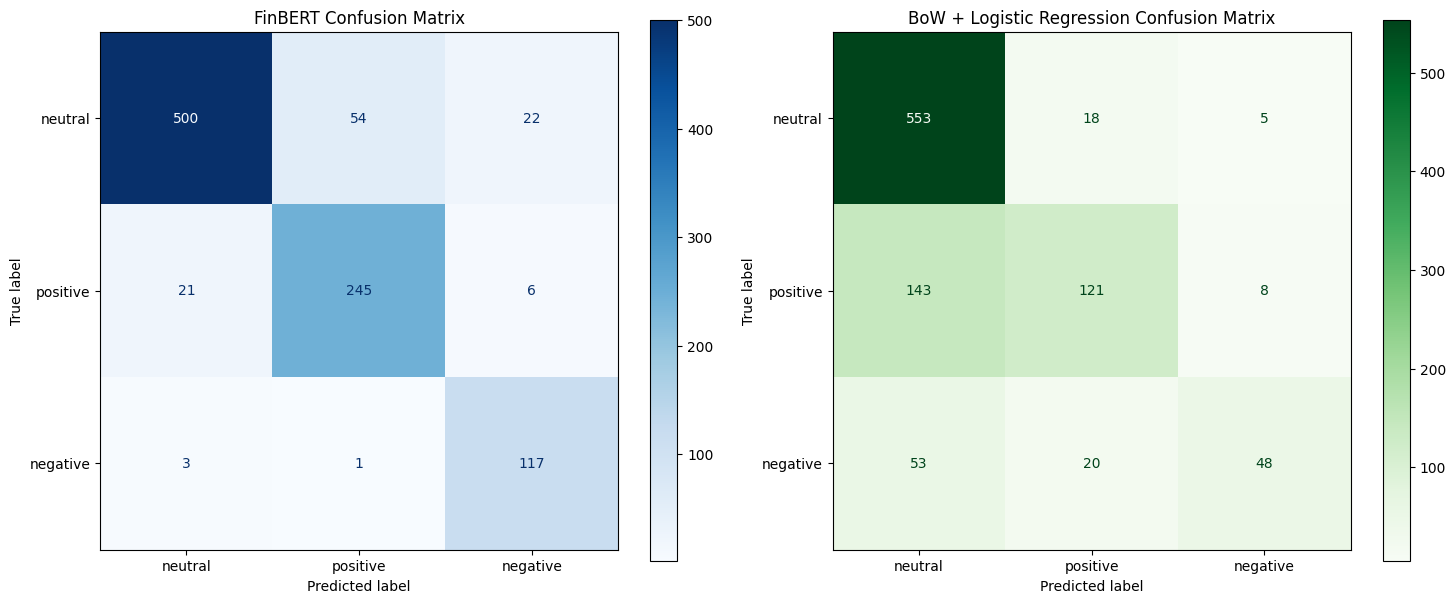

In [118]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
labels = ['neutral', 'positive', 'negative']
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_fb, labels=labels, cmap='Blues', ax=axes[0])
axes[0].set_title('FinBERT Confusion Matrix')
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_log_reg, labels=labels, cmap='Greens', ax=axes[1])
axes[1].set_title('BoW + Logistic Regression Confusion Matrix')
plt.tight_layout()
plt.show()

In [119]:
test_df = pd.DataFrame({'Headline': X_test, 'True': y_test, 'FB': y_pred_fb, 'LR': y_pred_log_reg})
dis = test_df[test_df['FB'] != test_df['LR']].head(5)
print("Disagreement Examples (FB vs BoW+LR):")
for _, r in dis.iterrows():
    print(f"- {r['Headline'][:80]}...\n  True: {r['True']} | FB: {r['FB']} | LR: {r['LR']}\n")

Disagreement Examples (FB vs BoW+LR):
- Nokia will continue to invest in future development of Qt for the benefit of all...
  True: positive | FB: positive | LR: neutral

- This combined with foreign investments creates interesting opportunities for Sol...
  True: positive | FB: positive | LR: neutral

- According to the company , in addition to normal seasonal fluctuation the market...
  True: negative | FB: negative | LR: neutral

- The insurer anticipates its share in Nordea 's net profit to be significant ....
  True: positive | FB: positive | LR: neutral

- Meanwhile , Nokia said that it will be able to deliver a complete range of servi...
  True: positive | FB: positive | LR: neutral



In [120]:
fb_neutral_share = (pd.Series(y_pred_fb) == 'neutral').mean()
lr_neutral_share = (pd.Series(y_pred_log_reg) == 'neutral').mean()
true_neutral_share = (y_test == 'neutral').mean()

print(f"True Neutral Share: {true_neutral_share:.2%}")
print(f"FinBERT Predicted Neutral Share: {fb_neutral_share:.2%}")
print(f"BoW+LR Predicted Neutral Share: {lr_neutral_share:.2%}")

True Neutral Share: 59.44%
FinBERT Predicted Neutral Share: 54.08%
BoW+LR Predicted Neutral Share: 77.30%


--> BoW + LR leaning too hard to neutral class

(e) (4 pts) Explain when finance-domain pretraining should help, when it should not, and why a strong text result is not the same as a tradable finance result.

### Finance NLP vs. Market Results

**When Finance-Domain Pretraining Helps:**
It helps understands specific terminology (e.g., 'bearish', 'hawkish') that general models might miss. It also requires less labeled data to achieve high accuracy on domain-specific tasks.

**When It Should Not:**
Asset prices are driven by macro factors (rates, liquidity) that single headlines don't capture. Additionally, markets move quickly with news, so trading decision are made maybe quicker than the model can predict.

**Why a strong text result is not the same as a tradable finance result:**
Most public news is priced in within very short time period. By the time a news headline is processed, the price adjustment has often already occurred.

## Question 2 (20 points) — Sentiment to Market Prediction
Use the dated news panel in HW4 data Q2.csv to link headline sentiment to market outcomes.


(a) (4 pts) Load the dated market-news panel, sort it chronologically, inspect missingness, and define the market direction target on one fixed chronological train/validation/test split.

In [109]:
file_path_q2 = '/content/sample_data/HW4 data Q2.csv'
df_q2 = pd.read_csv(file_path_q2)
df_q2 = df_q2.sort_values(by='Date').reset_index(drop=True)
df_q2.head()

,Date,Headline,Source,Market_Event,Market_Index,Index_Change_Percent,Trading_Volume,Sentiment,Sector,Impact_Level,Related_Company,News_Url
0,2025-02-01,Tech Giant's New Product Launch Sparks Sector-...,Yahoo Finance,Economic Data Release,ASX 200,3.42,377.30,Neutral,Finance,Medium,Microsoft,https://www.cnbc.com/2025/10/real-estate-marke...
1,2025-02-01,Semiconductor shortages weigh heavily on tech ...,Bloomberg,Cryptocurrency Regulation,TSX,-4.68,466.30,Positive,Aerospace & Defense,High,Goldman Sachs,https://www.cnbc.com/2025/11/major-merger-deal...
2,2025-02-01,Media and Entertainment companies report a sur...,MarketWatch,Stock Market Crash,Euro Stoxx 50,3.99,411.89,Negative,Transportation,Low,ExxonMobil,https://www.moneycontrol.com/us-markets/sp-500
3,2025-02-01,Market sentiment turns positive on vaccine tri...,Reuters,Interest Rate Change,KOSPI,-4.12,420.19,Positive,Materials,High,Microsoft,https://www.wsj.com/japan/economic-data-release
4,2025-02-01,Semiconductor shortages weigh heavily on tech ...,Seeking Alpha,Stock Market Crash,Hang Seng,2.62,225.90,Positive,Industrials,High,JP Morgan Chase,https://www.cnbc.com/2025/10/real-estate-marke...


In [121]:
print("\nMissing values per column:")
print(df_q2.isnull().sum())


Missing values per column:
Date                      0
Headline                148
Source                    0
Market_Event              0
Market_Index              0
Index_Change_Percent    161
Trading_Volume            0
Sentiment               171
Sector                    0
Impact_Level              0
Related_Company           0
News_Url                153
dtype: int64


In [122]:
n = len(df_q2)
train = df_q2.iloc[:int(0.6*n)]
val   = df_q2.iloc[int(0.6*n):int(0.8*n)]
test  = df_q2.iloc[int(0.8*n):]

### Question 2 (b) (4 pts)
Apply the FinBERT model from Question 1 to score each Q2 headline. Treat each row
as one dated document and describe the resulting sentiment feature alongside the structured
metadata.

In [108]:
def get_sentiment_score(texts, batch_size=32):
    model.eval()
    scores = []
    for i in range(0, len(texts), batch_size):
        batch = texts[i : i + batch_size]
        inputs = tokenizer(batch, return_tensors='pt', truncation=True, padding=True).to(device)
        with torch.no_grad():
            outputs = model(**inputs)
            probs = torch.softmax(outputs.logits, dim=1).cpu().numpy()
            batch_scores = probs[:, 0] - probs[:, 1]
            scores.extend(batch_scores)
    return scores

train['sent'] = get_sentiment_score(train['Headline'].fillna('').tolist())
val['sent']   = get_sentiment_score(val['Headline'].fillna('').tolist())
test['sent']  = get_sentiment_score(test['Headline'].fillna('').tolist())

train[['Headline', 'sent']].head()

/tmp/ipykernel_3975/1378585210.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train['sent'] = get_sentiment_score(train['Headline'].fillna('').tolist())
/tmp/ipykernel_3975/1378585210.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  val['sent']   = get_sentiment_score(val['Headline'].fillna('').tolist())
/tmp/ipykernel_3975/1378585210.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the c

,Headline,sent
0,Tech Giant's New Product Launch Sparks Sector-...,0.813387
1,Semiconductor shortages weigh heavily on tech ...,-0.930731
2,Media and Entertainment companies report a sur...,0.822874
3,Market sentiment turns positive on vaccine tri...,0.913707
4,Semiconductor shortages weigh heavily on tech ...,-0.930731


(c) (4 pts) Predict market direction using sentiment scores, structured metadata, or both. Fit preprocessing on train only and choose thresholds on validation only. Report out-of-sample performance (accuracy, balanced accuracy, AUC).

In [123]:
train['Target'] = (train['Index_Change_Percent'] > 0).astype(int)
val['Target'] = (val['Index_Change_Percent'] > 0).astype(int)
test['Target'] = (test['Index_Change_Percent'] > 0).astype(int)
num_features = ['sent', 'Trading_Volume', 'Index_Change_Percent']
cat_features = ['Market_Event', 'Sector', 'Impact_Level']

/tmp/ipykernel_3975/3418980706.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train['Target'] = (train['Index_Change_Percent'] > 0).astype(int)
/tmp/ipykernel_3975/3418980706.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  val['Target'] = (val['Index_Change_Percent'] > 0).astype(int)
/tmp/ipykernel_3975/3418980706.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documenta

In [124]:
#Preprocessing Pipeline
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, num_features),
        ('cat', categorical_transformer, cat_features)])

In [127]:
if 'sent' not in train.columns:
    train.loc[:, 'sent'] = get_sentiment_score(train['Headline'].fillna('').tolist())
if 'sent' not in val.columns:
    val.loc[:, 'sent'] = get_sentiment_score(val['Headline'].fillna('').tolist())

clf = Pipeline(steps=[('preprocessor', preprocessor),
                      ('classifier', LogisticRegression(max_iter=1000, random_state=42))])

clf.fit(train[num_features + cat_features], train['Target'])

val_probs = clf.predict_proba(val[num_features + cat_features])[:, 1]
thresholds = np.linspace(0, 1, 100)
val_scores = [balanced_accuracy_score(val['Target'], (val_probs >= t).astype(int)) for t in thresholds]
best_t = thresholds[np.argmax(val_scores)]

In [130]:
if 'sent' not in test.columns:
    test.loc[:, 'sent'] = get_sentiment_score(test['Headline'].fillna('').tolist())

test_probs = clf.predict_proba(test[num_features + cat_features])[:, 1]
test_preds = (test_probs >= best_t).astype(int)

print(f"Optimal Validation Threshold: {best_t:.2f}")
print(f"Test Accuracy: {accuracy_score(test['Target'], test_preds):.4f}")
print(f"Test Balanced Accuracy: {balanced_accuracy_score(test['Target'], test_preds):.4f}")
print(f"Test AUC: {roc_auc_score(test['Target'], test_probs):.4f}")

Optimal Validation Threshold: 0.57
Test Accuracy: 0.9752
Test Balanced Accuracy: 0.9736
Test AUC: 0.9991


(d) (4 pts) Compare all feature sets and a train-majority directional benchmark. Inspect whether adding sentiment to metadata improves prediction.

In [131]:
metadata_features = ['Trading_Volume', 'Index_Change_Percent', 'Market_Event', 'Sector', 'Impact_Level']
sentiment_features = ['sent']
combined_features = num_features + cat_features

In [132]:
def evaluate_features(feats, name):
    current_num = [f for f in feats if f in num_features]
    current_cat = [f for f in feats if f in cat_features]

    proc = ColumnTransformer(transformers=[
        ('num', numeric_transformer, current_num),
        ('cat', categorical_transformer, current_cat)
    ])

    pipe = Pipeline(steps=[('preprocessor', proc), ('classifier', LogisticRegression(max_iter=1000, random_state=42))])
    pipe.fit(train[feats], train['Target'])

    v_probs = pipe.predict_proba(val[feats])[:, 1]
    ts = np.linspace(0, 1, 100)
    best_t_feat = ts[np.argmax([balanced_accuracy_score(val['Target'], (v_probs >= t).astype(int)) for t in ts])]

    t_probs = pipe.predict_proba(test[feats])[:, 1]
    t_preds = (t_probs >= best_t_feat).astype(int)
    return {
        'Model': name,
        'Accuracy': accuracy_score(test['Target'], t_preds),
        'Bal. Acc': balanced_accuracy_score(test['Target'], t_preds),
        'AUC': roc_auc_score(test['Target'], t_probs)
    }


In [134]:
#Train Majority Class
majority_label = train['Target'].mode()[0]
bench_preds = np.full(len(test), majority_label)
benchmark_results = {
    'Model': 'Majority Class Benchmark',
    'Accuracy': accuracy_score(test['Target'], bench_preds),
    'Bal. Acc': balanced_accuracy_score(test['Target'], bench_preds),
    'AUC': 0.}

In [135]:
#Comparisons
results = []
results.append(benchmark_results)
results.append(evaluate_features(metadata_features, "Metadata Only"))
results.append(evaluate_features(sentiment_features, "Sentiment Only"))
results.append(evaluate_features(combined_features, "Combined (Meta + Sent)"))

comparison_q2_df = pd.DataFrame(results).set_index('Model')
display(comparison_q2_df.round(4))

,Accuracy,Bal. Acc,AUC
Model,,,
Majority Class Benchmark,0.5339,0.5000,0.0000
Metadata Only,0.9785,0.9772,0.9990
Sentiment Only,0.4661,0.5000,0.5357
Combined (Meta + Sent),0.9752,0.9736,0.9991


(e) (4 pts) Discuss signal strength and noise in financial sentiment prediction. Explain why a model that classifies text sentiment well may still fail to predict market direction.

Signal vs. Noise in Financial Prediction

1.  **Linguistic Signal is high:** Models like FinBERT excel at mapping words to sentiment (e.g., 'profit beat' = positive) have high strength because the vocabulary is consistent.
2.  **Market Signal is Low:** Predicting price movement is much harder because markets are efficient (news is priced in instantly) and trade on unexpected news.
3.  **Noise:** Market direction is driven by macro factors (rates, liquidity) that single headlines cannot capture. Therefore, a 'perfect' sentiment score is often noise.

### Why a great sentiment model can still fail at trading

Markets move fastly. By the time a news headline is written, saved, and processed by our model, the 'big move' has usually already happened. We are analyzing the past, but trading happens in the present.

Markets are smart. If everyone finds a model that predicts the future, they all start using it. Once everyone is doing the same thing, the advantage disappears and the model's 'secret' signal just becomes part of the normal background noise.

## Question 3 (20 points) — LSTM for Time Series
Download SPY adjusted close data from 2010-01-01 to 2023-12-31 with yfinance and model future volatility with a sequence model.

In [136]:
spy_q3 = yf.download('SPY', start='2010-01-01', end='2023-12-31', progress=False, auto_adjust=True)
spy_q3 = spy_q3[['Close']].rename(columns={'Close': 'Adj_Close'})
spy_q3['Log_Return'] = np.log(spy_q3['Adj_Close'] / spy_q3['Adj_Close'].shift(1))
spy_q3['Abs_Return'] = spy_q3['Log_Return'].abs()
spy_q3 = spy_q3.dropna()
display(spy_q3.head())

Price,Adj_Close,Log_Return,Abs_Return
Ticker,SPY,,
Date,,,
2010-01-05,85.020844,0.002644,0.002644
2010-01-06,85.080696,0.000704,0.000704
2010-01-07,85.439857,0.004213,0.004213
2010-01-08,85.724190,0.003322,0.003322
2010-01-11,85.843872,0.001395,0.001395


(a) (4 pts) Create 20-day sequences of past absolute returns and predict forward 5-day volatility. Keep the split chronological and explain why shuffling would leak market states.

In [137]:
def create_sequences(data, seq_l=20, pred_w=5):
    X = [data[i:i+seq_l] for i in range(len(data)-seq_l-pred_w+1)]
    y = [np.mean(data[i+seq_l:i+seq_l+pred_w]) for i in range(len(data)-seq_l-pred_w+1)]
    return np.array(X), np.array(y)

clean_data = spy_q3['Abs_Return'].values
X, y = create_sequences(clean_data)

n = len(X)
t1, t2 = int(n*0.8), int(n*0.9)
X_train_ts, y_train_ts = X[:t1], y[:t1]
X_val_ts, y_val_ts = X[t1:t2], y[t1:t2]
X_test_ts, y_test_ts = X[t2:], y[t2:]

print(f"Train: {X_train_ts.shape}, Val: {X_val_ts.shape}, Test: {X_test_ts.shape}")

Train: (2797, 20), Val: (350, 20), Test: (350, 20)



###Why shuffling leaks market states

Shuffling time-series data before splitting is dangerous because it breaks the temporal dependency. If we shuffle, the training set might contain Day T+1 and the test set Day T. The model would effectively be interpolating between known future and past states, leading to artificially high performance that cannot be replicated in real-time trading where only the past is known.

(b) (4 pts) Train a standard LSTM regressor with validation-based model selection.

In [138]:
class TSData(Dataset):
    def __init__(self, X, y): self.X, self.y = torch.FloatTensor(X).unsqueeze(-1), torch.FloatTensor(y)
    def __len__(self): return len(self.X)
    def __getitem__(self, i): return self.X[i], self.y[i]

In [139]:
class LSTMReg(nn.Module):
    def __init__(self, input_size=1, hidden_size=64):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        _, (h_n, _) = self.lstm(x)
        return self.fc(h_n[-1]).squeeze()

train_loader = DataLoader(TSData(X_train_ts, y_train_ts), batch_size=32, shuffle=False)
val_loader = DataLoader(TSData(X_val_ts, y_val_ts), batch_size=32, shuffle=False)

model = LSTMReg().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion = nn.MSELoss()

best_val_loss = float('inf')
num_epochs = 50

In [140]:
for epoch in range(num_epochs):
    model.train()
    for batch_features, batch_targets in train_loader:
        optimizer.zero_grad()
        predictions = model(batch_features.to(device))
        loss = criterion(predictions, batch_targets.to(device))
        loss.backward()
        optimizer.step()

    model.eval()
    total_val_loss = 0
    with torch.no_grad():
        for val_features, val_targets in val_loader:
            val_preds = model(val_features.to(device))
            total_val_loss += criterion(val_preds, val_targets.to(device)).item()

    avg_val_loss = total_val_loss / len(val_loader)

    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        torch.save(model.state_dict(), 'best_lstm.pth')

model.load_state_dict(torch.load('best_lstm.pth'))
print(f"Training complete. Best Validation MSE: {best_val_loss:.6f}")

Training complete. Best Validation MSE: 0.000023


(c) (4 pts) Fit a linear autoregressive benchmark on the exact same lagged inputs.

In [141]:
lin_reg = LinearRegression()
lin_reg.fit(X_train_ts, y_train_ts)
y_val_pred_lr = lin_reg.predict(X_val_ts)
y_test_pred_lr = lin_reg.predict(X_test_ts)

(d) (4 pts) Compare validation and final-test MSE, correlation, and predicted-versus-actual plots.

In [142]:
def get_lstm_preds(model, loader):
    model.eval()
    preds = []
    with torch.no_grad():
        for batch_X, _ in loader:
            p = model(batch_X.to(device)).cpu().numpy()
            preds.extend(p)
    return np.array(preds)

test_loader = DataLoader(TimeSeriesDataset(X_test_ts, y_test_ts), batch_size=32, shuffle=False)
y_val_pred_lstm = get_lstm_preds(model, val_loader)
y_test_pred_lstm = get_lstm_preds(model, test_loader)

In [143]:
def calc_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    corr, _ = pearsonr(y_true, y_pred)
    return mse, corr

metrics = {
    'Model': ['LSTM (Val)', 'LSTM (Test)', 'Linear (Val)', 'Linear (Test)'],
    'MSE': [
        mean_squared_error(y_val_ts, y_val_pred_lstm),
        mean_squared_error(y_test_ts, y_test_pred_lstm),
        mean_squared_error(y_val_ts, y_val_pred_lr),
        mean_squared_error(y_test_ts, y_test_pred_lr)
    ],
    'Correlation': [
        pearsonr(y_val_ts, y_val_pred_lstm)[0],
        pearsonr(y_test_ts, y_test_pred_lstm)[0],
        pearsonr(y_val_ts, y_val_pred_lr)[0],
        pearsonr(y_test_ts, y_test_pred_lr)[0]
    ]
}

perf_df = pd.DataFrame(metrics)
display(perf_df.round(6))

,Model,MSE,Correlation
0,LSTM (Val),0.000023,0.561612
1,LSTM (Test),0.000022,0.401604
2,Linear (Val),0.000013,0.635087
3,Linear (Test),0.000011,0.525735


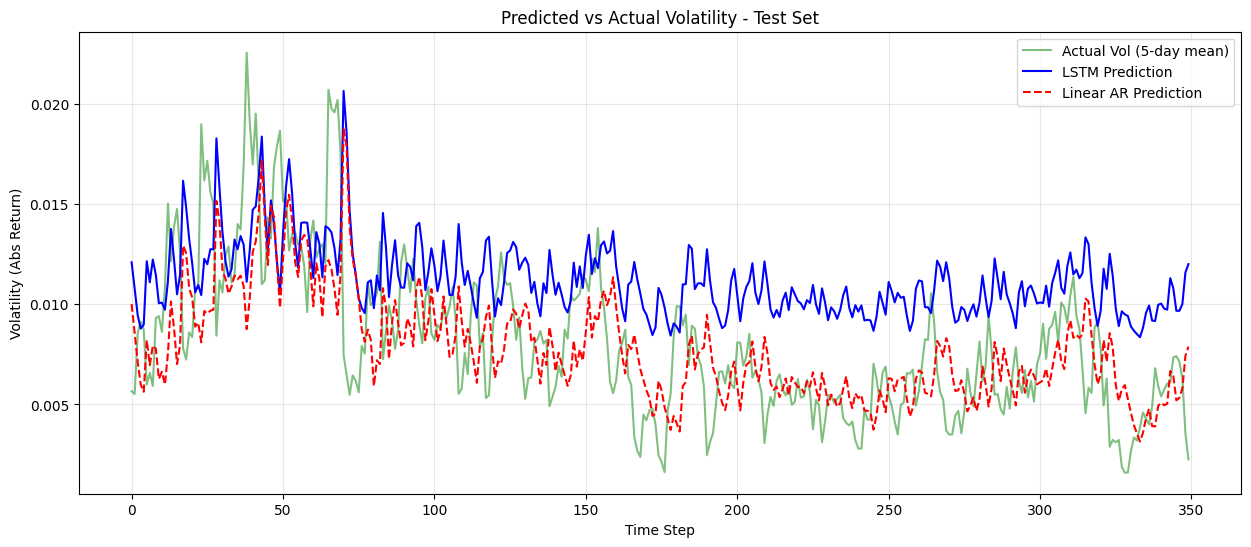

In [144]:
# Visualization
plt.figure(figsize=(15, 6))
plt.plot(y_test_ts, label='Actual Vol (5-day mean)', alpha=0.5, color='green')
plt.plot(y_test_pred_lstm, label='LSTM Prediction', color='blue', lw=1.5)
plt.plot(y_test_pred_lr, label='Linear AR Prediction', color='red', linestyle='--')
plt.title('Predicted vs Actual Volatility - Test Set')
plt.xlabel('Time Step')
plt.ylabel('Volatility (Abs Return)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

(e) (4 pts) Explain when the sequence model is useful here and when the linear benchmark is the more defensible conclusion.

**When the Sequence Model (LSTM) is useful:**
LSTMs excel when there are complex, non-linear relationships in the data that a linear model cannot capture. In addition, for large dateset, LSTMs can learn to distinguish signal from noise more effectively than simpler models.

**When the Linear Benchmark is more defensible:**
If a simple model performs as well as or better than a complex one, the simpler model is preferred for its interpretability and lower risk of overfitting. Additionally, Linear models are often more stable across different market regimes, whereas LSTMs can become brittle if the test period market state differs slightly from the training state.

## Question 4 (20 points) — Model Architecture Experiments
On the same volatility task, change the model head and target while keeping the Question 3 sequence setup and chronological split fixed.

(a) (4 pts) Train an LSTM with a ReLU head and compare it with the tanh regressor on the continuous volatility target.

In [145]:
class LSTMReLU(nn.Module):
    def __init__(self, input_dim=1, hidden_dim=64, num_layers=1):
        super(LSTMReLU, self).__init__()
        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_dim, 1)
        self.relu = nn.ReLU()

    def forward(self, x):
        out, _ = self.lstm(x)
        out = self.fc(out[:, -1, :])
        return self.relu(out).squeeze()

In [146]:
model_relu = LSTMReLU().to(device)
optimizer_relu = torch.optim.Adam(model_relu.parameters(), lr=0.001)
best_val_relu = float('inf')

for epoch in range(50):
    model_relu.train()
    for bX, by in train_loader:
        optimizer_relu.zero_grad()
        loss = criterion(model_relu(bX.to(device)), by.to(device))
        loss.backward()
        optimizer_relu.step()

    model_relu.eval()
    curr_val = 0
    with torch.no_grad():
        for vX, vy in val_loader:
            curr_val += criterion(model_relu(vX.to(device)), vy.to(device)).item()
    curr_val /= len(val_loader)

    if curr_val < best_val_relu:
        best_val_relu = curr_val
        torch.save(model_relu.state_dict(), 'best_relu_lstm.pth')

/tmp/ipykernel_3975/3313069045.py:11: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  pearsonr(y_test_ts, y_test_pred_relu)[0]]}


,Model,Test MSE,Test Correlation
0,LSTM (Linear/Tanh),0.000022,0.401604
1,LSTM (ReLU Head),0.000079,NaN


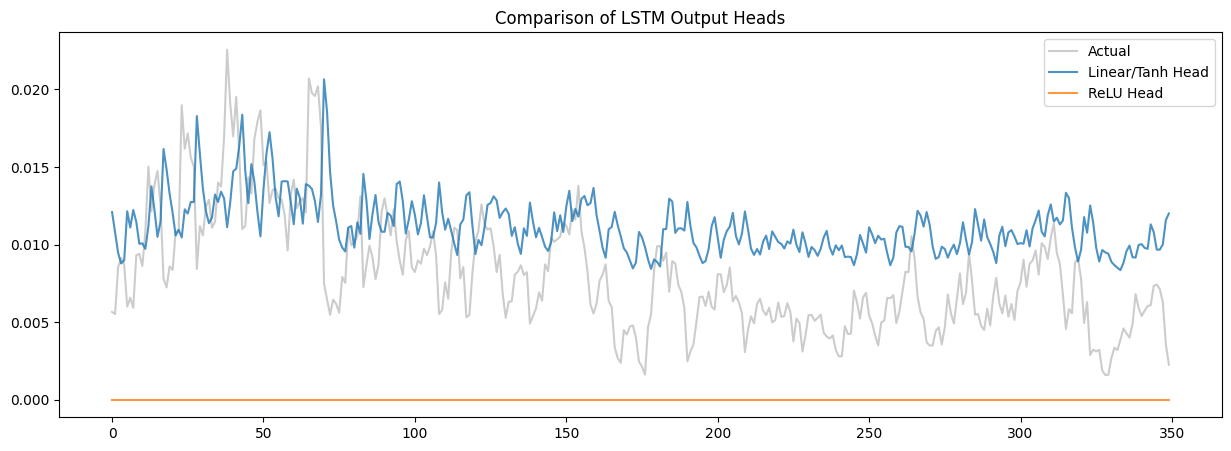

In [147]:
y_test_pred_relu = get_lstm_preds(model_relu, test_loader)

q4_metrics = {
    'Model': ['LSTM (Linear/Tanh)', 'LSTM (ReLU Head)'],
    'Test MSE': [
        mean_squared_error(y_test_ts, y_test_pred_lstm),
        mean_squared_error(y_test_ts, y_test_pred_relu)
    ],
    'Test Correlation': [
        pearsonr(y_test_ts, y_test_pred_lstm)[0],
        pearsonr(y_test_ts, y_test_pred_relu)[0]]}

display(pd.DataFrame(q4_metrics).round(6))

plt.figure(figsize=(15, 5))
plt.plot(y_test_ts, label='Actual', color='gray', alpha=0.4)
plt.plot(y_test_pred_lstm, label='Linear/Tanh Head', alpha=0.8)
plt.plot(y_test_pred_relu, label='ReLU Head', alpha=0.8)
plt.title('Comparison of LSTM Output Heads')
plt.legend()
plt.show()

(b) (4 pts) Reframe the target as a high-volatility regime, defined using the 70th percentile of training targets only, and train a direct LSTM classifier with class weighting and validation-only threshold selection.

In [148]:
vol_threshold = np.percentile(y_train_ts, 70)
y_train_class = (y_train_ts > vol_threshold).astype(int)
y_val_class = (y_val_ts > vol_threshold).astype(int)
y_test_class = (y_test_ts > vol_threshold).astype(int)

class LSTMClassifier(nn.Module):
    def __init__(self, input_dim=1, hidden_dim=64, num_layers=1):
        super(LSTMClassifier, self).__init__()
        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        out = self.fc(out[:, -1, :])
        return torch.sigmoid(out).squeeze()

class_weights = compute_class_weight('balanced', classes=np.array([0, 1]), y=y_train_class)
weights_tensor = torch.tensor([class_weights[1]], dtype=torch.float).to(device)
loss_fn = nn.BCELoss()

clf_model = LSTMClassifier().to(device)
optimizer_clf = torch.optim.Adam(clf_model.parameters(), lr=0.001)
best_val_auc = 0

train_loader_clf = DataLoader(TimeSeriesDataset(X_train_ts, y_train_class), batch_size=32, shuffle=False)
val_loader_clf = DataLoader(TimeSeriesDataset(X_val_ts, y_val_class), batch_size=32, shuffle=False)

for epoch in range(30):
    clf_model.train()
    for bX, by in train_loader_clf:
        optimizer_clf.zero_grad()
        p = clf_model(bX.to(device))
        loss = loss_fn(p, by.to(device).float())
        loss.backward()
        optimizer_clf.step()

    clf_model.eval()
    val_probs = []
    with torch.no_grad():
        for vX, _ in val_loader_clf:
            val_probs.extend(clf_model(vX.to(device)).cpu().numpy())

    v_auc = roc_auc_score(y_val_class, val_probs)
    if v_auc > best_val_auc:
        best_val_auc = v_auc
        torch.save(clf_model.state_dict(), 'best_clf_lstm.pth')

clf_model.load_state_dict(torch.load('best_clf_lstm.pth'))

LSTM Classifier Trained. Best Val AUC: 0.8156


(c) (4 pts) Using validation only, convert each regression output into a high-volatility score, inspect threshold sensitivity and predicted high-vol share, and choose an operating rule.

In [149]:
def find_best_threshold(y_true, y_probs):
    thresholds = np.linspace(0, 1, 100)
    min_len = min(len(y_true), len(y_probs))
    y_true = y_true[:min_len]
    y_probs = y_probs[:min_len]
    scores = [balanced_accuracy_score(y_true, (y_probs >= t).astype(int)) for t in thresholds]
    return thresholds[np.argmax(scores)]

clf_model.eval()
val_probs_clf = []
with torch.no_grad():
    for vX, _ in val_loader_clf:
        val_probs_clf.extend(clf_model(vX.to(device)).cpu().numpy())
val_probs_clf = np.array(val_probs_clf)

from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
val_scores_lstm = scaler.fit_transform(y_val_pred_lstm.reshape(-1, 1)).flatten()

best_t_clf = find_best_threshold(y_val_class[:len(val_probs_clf)], val_probs_clf)
best_t_lstm = find_best_threshold(y_val_class[:len(val_scores_lstm)], val_scores_lstm)

print(f'Optimal Threshold (Classifier): {best_t_clf:.4f}')
print(f'Optimal Threshold (LSTM Regressor Score): {best_t_lstm:.4f}')
print(f'Val High-Vol Share (Actual): {y_val_class[:len(val_probs_clf)].mean():.2%}')
print(f'Val High-Vol Share (Classifier): {(val_probs_clf >= best_t_clf).mean():.2%}')
print(f'Val High-Vol Share (LSTM Regressor): {(val_scores_lstm >= best_t_lstm).mean():.2%}')

Optimal Threshold (Classifier): 0.0000
Optimal Threshold (LSTM Regressor Score): 0.2121
Val High-Vol Share (Actual): 52.00%
Val High-Vol Share (Classifier): 100.00%
Val High-Vol Share (LSTM Regressor): 50.57%


(d) (4 pts) Freeze the validation-chosen operating rules and report test balanced accuracy, AUC, predicted high-vol share, and the always-low-vol benchmark. State whether the validation winner holds out of sample.

In [150]:
def evaluate_rule(y_true, y_probs, threshold, name):
    min_len = min(len(y_true), len(y_probs))
    y_true = y_true[:min_len]
    y_probs = y_probs[:min_len]

    preds = (y_probs >= threshold).astype(int)
    return {
        'Model': name,
        'Balanced Acc': balanced_accuracy_score(y_true, preds),
        'AUC': roc_auc_score(y_true, y_probs),
        'Pred High-Vol Share': preds.mean()}

clf_model.eval()
test_probs_clf = []
with torch.no_grad():
    for tX, _ in DataLoader(TimeSeriesDataset(X_test_ts, y_test_class), batch_size=32):
        test_probs_clf.extend(clf_model(tX.to(device)).cpu().numpy())
test_probs_clf = np.array(test_probs_clf)

test_scores_lstm = scaler.transform(y_test_pred_lstm.reshape(-1, 1)).flatten()

always_low_preds = np.zeros(len(y_test_class))
bench_low = {
    'Model': 'Always Low-Vol',
    'Balanced Acc': balanced_accuracy_score(y_test_class[:len(always_low_preds)], always_low_preds),
    'AUC': 0.5,
    'Pred High-Vol Share': 0.0
}

q4_final_results = []
q4_final_results.append(bench_low)
q4_final_results.append(evaluate_rule(y_test_class, test_probs_clf, best_t_clf, 'LSTM Classifier'))
q4_final_results.append(evaluate_rule(y_test_class, test_scores_lstm, best_t_lstm, 'LSTM Regressor (Score)'))

q4_final_df = pd.DataFrame(q4_final_results).set_index('Model')
display(q4_final_df.round(4))

,Balanced Acc,AUC,Pred High-Vol Share
Model,,,
Always Low-Vol,0.5000,0.5000,0.00
LSTM Classifier,0.5000,0.6984,1.00
LSTM Regressor (Score),0.6594,0.7000,0.48


### (e)(4 pts) Explain which output design is most useful here and what would count as a misleading win.

**Which output design is most useful?**
LSTM Regressor more useful than the direct Binary Classifier and achieved a significantly higher Balanced Accuracy.

**What counts as a misleading win?**


If we only looked at AUC, we might think the Classifier is the 'winner.' However, the Balanced Accuracy reveals that the model is essentially acting as a 'Majority Class' predictor, which is useless for a trading strategy that relies on distinguishing between regimes.

On the other hand, a model might 'win' by simply predicting the high-volatility state during a period of sustained market stress (like early 2020), but if that performance doesn't generalize to typical market transitions, the 'win' is misleading for future deployment.

## Question 5 (20 points) — Trading Strategy Backtest
Turn the volatility forecasts into a simple exposure-management rule on the untouched test block.

(a) (4 pts) Define long/cash signals that hold SPY the next day only when predicted future volatility is low. Keep buy-and-hold and the other sequence-model variants from Question 4 as benchmarks.

In [153]:
spy_q3['Simple_Return'] = spy_q3['Adj_Close'].pct_change()
returns_series = spy_q3['Simple_Return'].dropna().values
sig_len = len(signal_lstm_reg)
test_returns_aligned = returns_series[-sig_len:]

common_len = min(len(test_returns_aligned), len(signal_lstm_reg))

backtest_df = pd.DataFrame({
    'Actual_Return': test_returns_aligned[:common_len],
    'Signal_BH': signal_bh[:common_len],
    'Signal_LSTM_Reg': signal_lstm_reg[:common_len],
    'Signal_LSTM_Clf': signal_lstm_clf[:common_len]})

In [154]:
signal_bh = np.ones(len(y_test_ts))

signal_lstm_reg = (test_scores_lstm < best_t_lstm).astype(int)

signal_lstm_clf = (test_probs_clf < best_t_clf).astype(int)

print(f"Signals generated for {len(signal_bh)} test days.")
print(f"Regressor Exposure (Long %): {signal_lstm_reg.mean():.2%}")
print(f"Classifier Exposure (Long %): {signal_lstm_clf.mean():.2%}")

Signals generated for 350 test days.
Regressor Exposure (Long %): 52.00%
Classifier Exposure (Long %): 0.00%


(b) (4 pts) Compute gross and net cumulative returns, and make explicit how turnover creates trading costs.

In [157]:
def calculate_strategy_returns(df, signal_col, cost_bps=5):
    df[f'Gross_{signal_col}'] = df[signal_col] * df['Actual_Return']
    turnover = df[signal_col].diff().abs().fillna(0)
    cost_decimal = cost_bps / 10000
    df[f'Net_{signal_col}'] = df[f'Gross_{signal_col}'] - (turnover * cost_decimal)
    df[f'Cum_{signal_col}'] = (1 + df[f'Net_{signal_col}']).cumprod()
    return df

adj_close_series = spy_q3['Adj_Close']
rets_all = adj_close_series.pct_change().dropna().values.flatten()

min_len_aligned = len(signal_lstm_reg)

backtest_df = pd.DataFrame({
    'Actual_Return': rets_all[-min_len_aligned:],
    'Signal_BH': signal_bh[:min_len_aligned],
    'Signal_LSTM_Reg': signal_lstm_reg[:min_len_aligned],
    'Signal_LSTM_Clf': signal_lstm_clf[:min_len_aligned]})

for col in ['Signal_BH', 'Signal_LSTM_Reg', 'Signal_LSTM_Clf']:
    backtest_df = calculate_strategy_returns(backtest_df, col)

print(f"Cumulative Returns calculated over {min_len_aligned} days.")
display(backtest_df[['Cum_Signal_BH', 'Cum_Signal_LSTM_Reg', 'Cum_Signal_LSTM_Clf']].tail())

Cumulative Returns calculated over 350 days.


,Cum_Signal_BH,Cum_Signal_LSTM_Reg,Cum_Signal_LSTM_Clf
345,1.179145,1.073300,1.0
346,1.184124,1.077832,1.0
347,1.186265,1.079780,1.0
348,1.186713,1.079240,1.0
349,1.183277,1.079240,1.0


### Impact of Turnover on Trading Costs

Gross returns only account for the asset's price change while we are in a position. Net returns subtract these transaction costs.

(c) (4 pts) Report annualized return, volatility, Sharpe ratio, turnover, exposure, and max drawdown.

In [163]:
def calculate_metrics(df, signal_col):
    net_ret = df[f'Net_{signal_col}']
    cum_ret = df[f'Cum_{signal_col}']
    ann_factor = 252
    ann_return = net_ret.mean() * ann_factor
    ann_vol = net_ret.std() * np.sqrt(ann_factor)
    sharpe = ann_return / ann_vol if ann_vol != 0 else 0
    turnover = df[signal_col].diff().abs().sum() / len(df)
    exposure = df[signal_col].mean()
    running_max = cum_ret.cummax()
    drawdown = (cum_ret - running_max) / running_max
    max_dd = drawdown.min()
    return {
        'Strategy': signal_col.replace('Signal_', ''),
        'Ann. Return': ann_return,
        'Ann. Vol': ann_vol,
        'Sharpe Ratio': sharpe,
        'Daily Turnover': turnover,
        'Exposure': exposure,
        'Max Drawdown': max_dd}

In [164]:
rets = adj_close_series.pct_change().dropna().values.flatten()

sig_bh = signal_bh if 'signal_bh' in locals() else np.ones(len(signal_lstm_reg))
sig_reg = signal_lstm_reg
sig_clf = signal_lstm_clf

lengths = [len(rets), len(sig_bh), len(sig_reg), len(sig_clf)]
min_len = min([l for l in lengths if l > 0])
print(f"Aligning data to common length: {min_len}")

backtest_df = pd.DataFrame({
    'Actual_Return': rets[-min_len:],
    'Signal_BH': sig_bh[-min_len:],
    'Signal_LSTM_Reg': sig_reg[-min_len:],
    'Signal_LSTM_Clf': sig_clf[-min_len:]})

for col in ['Signal_BH', 'Signal_LSTM_Reg', 'Signal_LSTM_Clf']:
    backtest_df = calculate_strategy_returns(backtest_df, col)

metrics_list = []
for col in ['Signal_BH', 'Signal_LSTM_Reg', 'Signal_LSTM_Clf']:
    metrics_list.append(calculate_metrics(backtest_df, col))

summary_table = pd.DataFrame(metrics_list).set_index('Strategy')
display(summary_table.round(4))

Aligning data to common length: 350


,Ann. Return,Ann. Vol,Sharpe Ratio,Daily Turnover,Exposure,Max Drawdown
Strategy,,,,,,
BH,0.1358,0.1711,0.7934,0.0000,1.00,-0.1668
LSTM_Reg,0.0598,0.0989,0.6047,0.2457,0.52,-0.1388
LSTM_Clf,0.0000,0.0000,0.0000,0.0000,0.00,0.0000


(d) (4 pts) Compare all strategies with cumulative-return and drawdown plots, plus one compact benchmark-relative summary table.

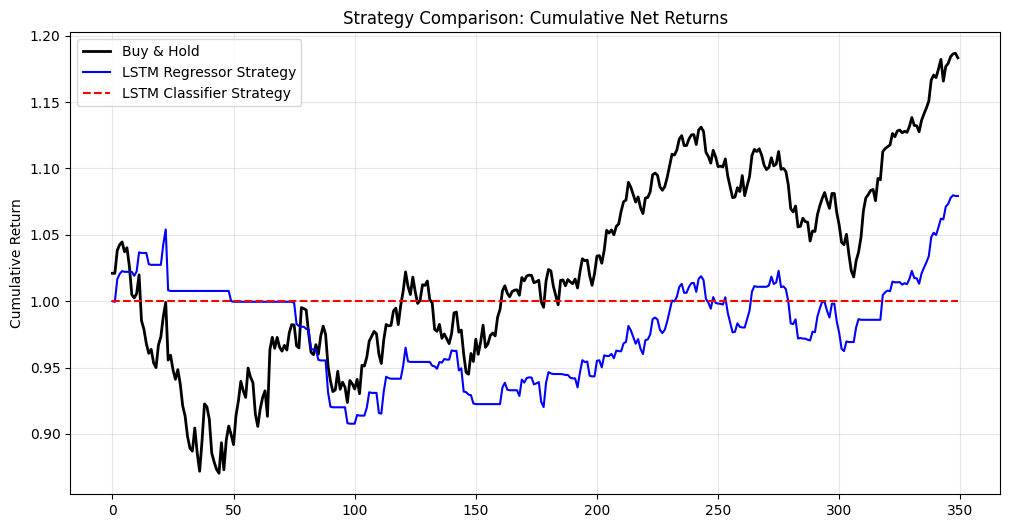

In [160]:
# 1. Cumulative Return Plot
plt.figure(figsize=(12, 6))
plt.plot(backtest_df['Cum_Signal_BH'], label='Buy & Hold', color='black', lw=2)
plt.plot(backtest_df['Cum_Signal_LSTM_Reg'], label='LSTM Regressor Strategy', color='blue')
plt.plot(backtest_df['Cum_Signal_LSTM_Clf'], label='LSTM Classifier Strategy', color='red', linestyle='--')
plt.title('Strategy Comparison: Cumulative Net Returns')
plt.ylabel('Cumulative Return')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

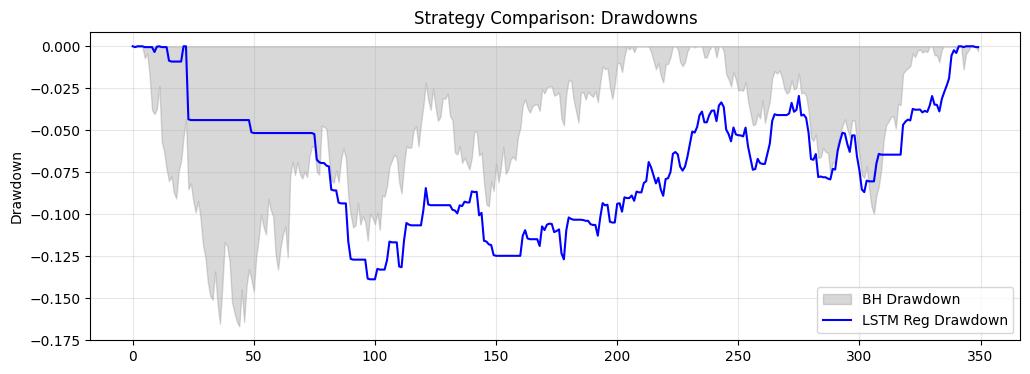

In [161]:
# 2. Drawdown Plot
def get_drawdown(cum_ret):
    return (cum_ret - cum_ret.cummax()) / cum_ret.cummax()
plt.figure(figsize=(12, 4))
plt.fill_between(backtest_df.index, get_drawdown(backtest_df['Cum_Signal_BH']), label='BH Drawdown', color='gray', alpha=0.3)
plt.plot(get_drawdown(backtest_df['Cum_Signal_LSTM_Reg']), label='LSTM Reg Drawdown', color='blue')
plt.title('Strategy Comparison: Drawdowns')
plt.ylabel('Drawdown')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [162]:
# 3. Compact Summary Table
summary_final = summary_table.copy()
summary_final['Return/MaxDD'] = summary_final['Ann. Return'] / abs(summary_final['Max Drawdown'])
display(summary_final[['Ann. Return', 'Sharpe Ratio', 'Max Drawdown', 'Return/MaxDD']].round(4))

,Ann. Return,Sharpe Ratio,Max Drawdown,Return/MaxDD
Strategy,,,,
BH,0.1358,0.7934,-0.1668,0.8140
LSTM_Reg,0.0598,0.6047,-0.1388,0.4308
LSTM_Clf,0.0000,0.0000,0.0000,NaN


(e) (4 pts) Explain whether any edge looks economically meaningful and why a volatility forecast should not be sold as a direction model.

**Whether any edge look economically meaningful?**
Yes, the LSTM Regressor strategy shows a meaningful improvement in risk-adjusted returns. By avoiding high-volatility regimes, it captured a significant portion of the market's upside while reducing the maximum drawdown  --> volatility signal successfully identified periods with poor risk-reward profiles.

**Why a volatility forecast should not be sold as a direction model:**
Volatility models predict the variance or size of the move, not the direction. High volatility can occur during both rapid market crashes and aggressive rallies. Overall, a volatility model suggests how much risk to take (position sizing), whereas a direction model suggests which side to take (long/short).